# Notebook 1: Data, EDA, Segmentasi, dan Suntikan Anomali

Notebook ini menyiapkan data untuk seluruh eksperimen berikutnya. Langkahnya: membaca data jumlah pemain Steam, membersihkannya, memotongnya menjadi segmen 20 hari, menyuntikkan anomali (mengikuti Rahadian et al., 2023), lalu membagi data menjadi train, validasi, dan test.

Jalankan dari atas ke bawah. Hasil disimpan ke `data/processed/`, `figures/`, dan `results/`.

## 1. Persiapan

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
SEG_LEN = 20          # panjang segmen (hari)
MAX_GAP = 3           # celah paling banyak 3 hari yang diisi interpolasi
BUMP_RATIO = 1.5      # batas "lonjakan asli": nilai maksimum > 1,5 x median segmen

ROOT = Path('..')
RAW, PROC, FIG, RES = ROOT/'data/raw', ROOT/'data/processed', ROOT/'figures', ROOT/'results'
for p in (PROC, FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

NAMES = {'dark_souls_3': 'Dark Souls 3', 'ets2': 'Euro Truck Simulator 2', 'garrys_mod': "Garry's Mod",
         'rainbow_six_siege': 'Rainbow Six Siege', 'stardew_valley': 'Stardew Valley', 'terraria': 'Terraria'}
GAMES = list(NAMES)
START_OVERRIDE = {'garrys_mod': '2012-01-01'}   # sebelum 2012 datanya terlalu bolong

## 2. Membaca dan membersihkan data

Aturan pembersihan (hasil pengecekan data sebelumnya):
1. Data diseragamkan ke harian dengan nilai maksimum per hari (bulan terakhir di file berinterval 1 jam dan 10 menit).
2. Hari terakhir (2025-06-21) dibuang karena datanya belum lengkap.
3. Data dipotong mulai hari pertama dengan pemain minimal 1.000, untuk membuang nilai 1 sampai 3 sebelum game rilis. Garry's Mod dimulai 2012-01-01.
4. Tanggal hilang diisi interpolasi linear hanya jika celahnya paling banyak 3 hari. Celah yang lebih panjang dibiarkan kosong.

In [2]:
def load_daily(game):
    d = pd.read_csv(RAW/f'{game}_player_counts.csv', encoding='utf-8-sig', parse_dates=['DateTime'])
    s = d.set_index('DateTime')['Players'].sort_index().resample('D').max()
    return s.iloc[:-1]

def fill_short_gaps(s, max_gap=MAX_GAP):
    isna = s.isna()
    run_id = (isna != isna.shift(fill_value=False)).cumsum()
    run_len = isna.groupby(run_id).transform('sum')
    interp = s.interpolate(limit_area='inside')
    fill = isna & (run_len <= max_gap)
    out = s.copy()
    out[fill] = interp[fill]
    return out, fill

daily, filled = {}, {}
info = []
for g in GAMES:
    s = load_daily(g)
    start = pd.Timestamp(START_OVERRIDE[g]) if g in START_OVERRIDE else s[s >= 1000].index[0]
    s = s[s.index >= start]
    n_missing = int(s.isna().sum())
    s, fill = fill_short_gaps(s)
    daily[g], filled[g] = s, fill
    info.append(dict(game=NAMES[g], mulai=start.date(), akhir=s.index[-1].date(), jumlah_hari=len(s),
                     hari_hilang=n_missing, diisi_interpolasi=int(fill.sum()),
                     tetap_kosong=int(s.isna().sum()), median_pemain=int(s.median())))
info = pd.DataFrame(info)
info

,game,mulai,akhir,jumlah_hari,hari_hilang,diisi_interpolasi,tetap_kosong,median_pemain
0,Dark Souls 3,2016-04-12,2025-06-20,3357,0,0,0,9546
1,Euro Truck Simulator 2,2013-01-01,2025-06-20,4554,110,1,109,29242
2,Garry's Mod,2012-01-01,2025-06-20,4920,25,4,21,35501
3,Rainbow Six Siege,2015-12-01,2025-06-20,3490,0,0,0,71573
4,Stardew Valley,2016-02-26,2025-06-20,3403,0,0,0,27131
5,Terraria,2011-05-15,2025-06-20,5151,52,1,51,26767


## 3. Visualisasi data (EDA)

Plot pertama memperlihatkan tren dan lonjakan tiap game. Plot kedua menumpuk semua game dengan sumbu log supaya perbedaan skalanya terlihat.

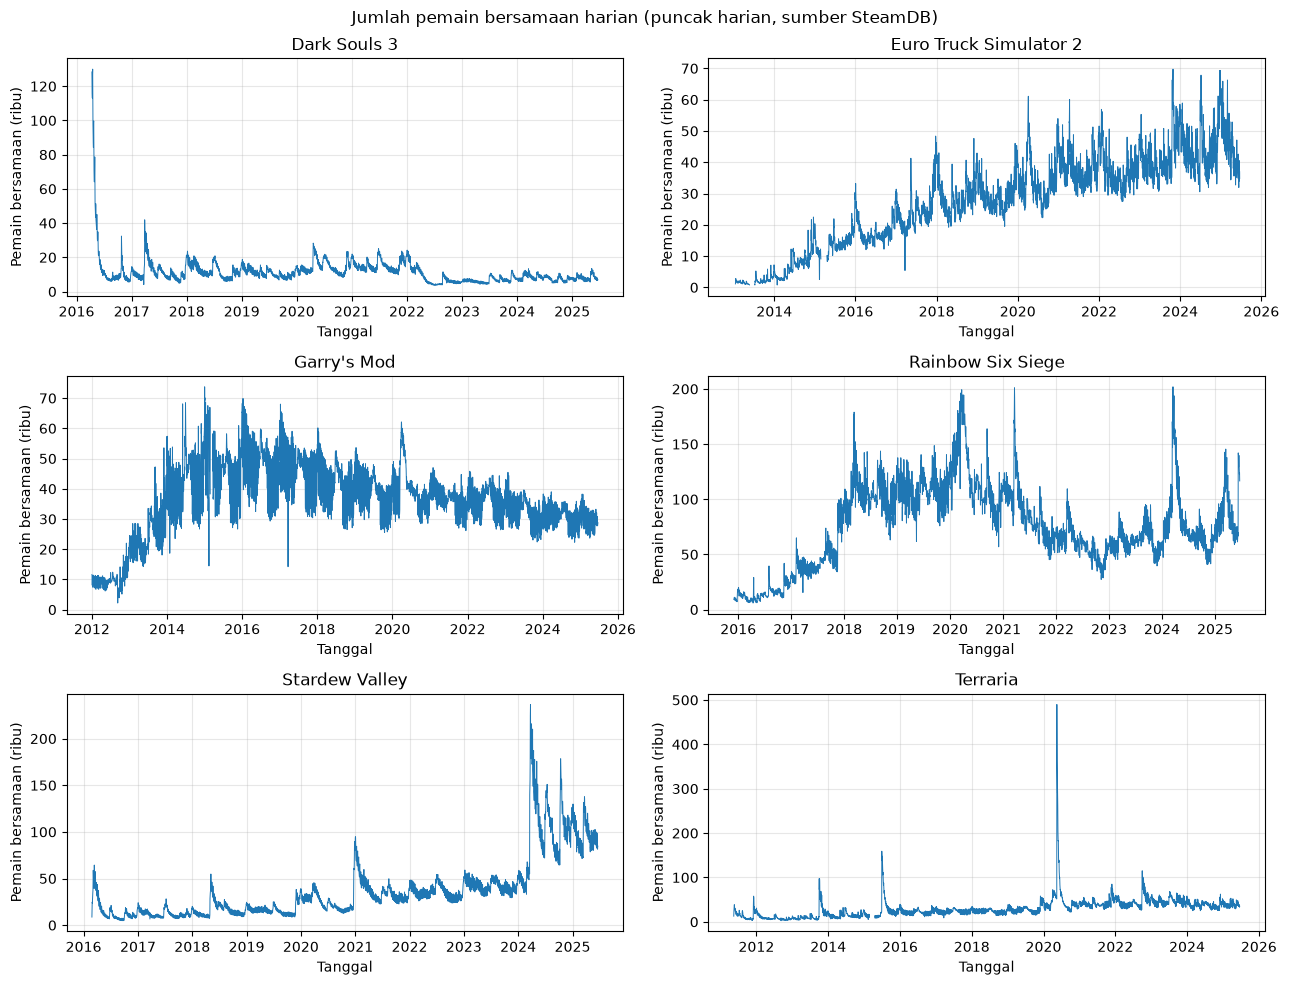

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, g in zip(axes.ravel(), GAMES):
    s = daily[g]
    ax.plot(s.index, s.values / 1000, lw=0.7)
    ax.set_title(NAMES[g]); ax.set_xlabel('Tanggal'); ax.set_ylabel('Pemain bersamaan (ribu)'); ax.grid(alpha=0.3)
fig.suptitle('Jumlah pemain bersamaan harian (puncak harian, sumber SteamDB)')
fig.tight_layout(); fig.savefig(FIG/'01_pemain_harian.png', dpi=150); plt.show()

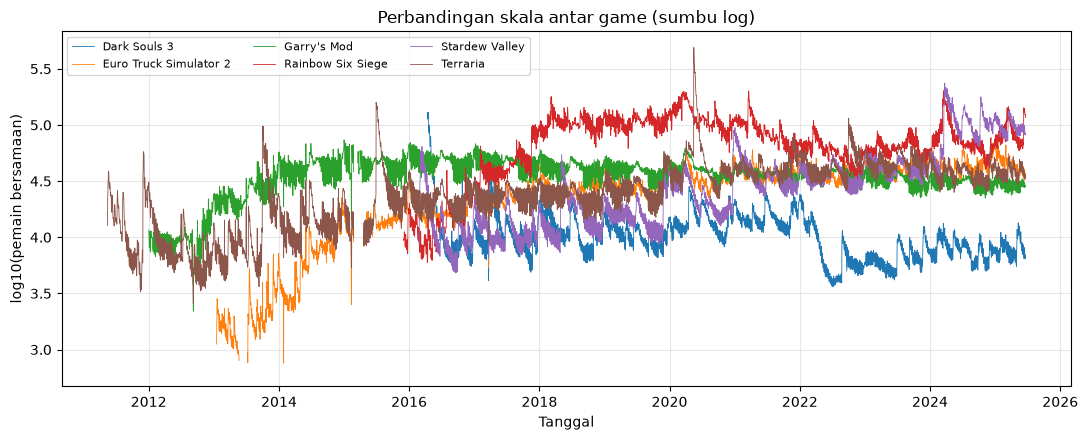

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for g in GAMES:
    ax.plot(daily[g].index, np.log10(daily[g].values), lw=0.6, label=NAMES[g])
ax.set_xlabel('Tanggal'); ax.set_ylabel('log10(pemain bersamaan)'); ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=8)
ax.set_title('Perbandingan skala antar game (sumbu log)')
fig.tight_layout(); fig.savefig(FIG/'02_skala_antar_game.png', dpi=150); plt.show()

## 4. Pola mingguan

Untuk menghilangkan pengaruh tren jangka panjang, tiap hari dibagi dengan rata-rata 7 hari di sekitarnya (nilai 1,0 berarti sama dengan rata-rata minggu itu). Setelah itu dihitung rata-rata per hari dalam seminggu untuk tiap game. Hari mengikuti zona waktu data SteamDB (UTC).

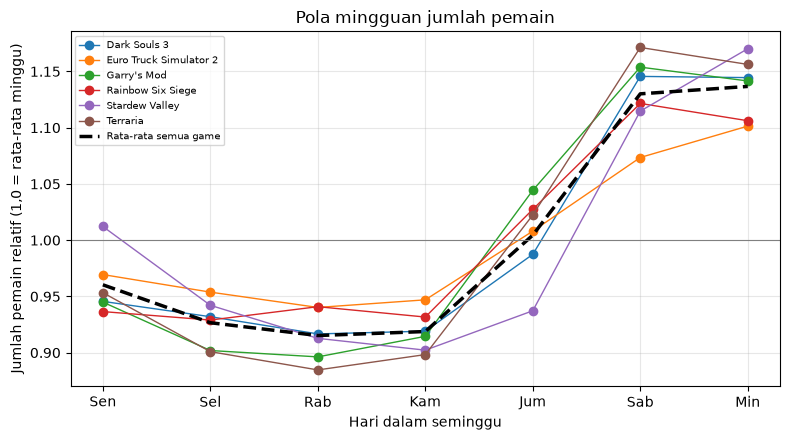

,Dark Souls 3,Euro Truck Simulator 2,Garry's Mod,Rainbow Six Siege,Stardew Valley,Terraria,Rata-rata semua game
Sen,0.946,0.969,0.945,0.937,1.012,0.953,0.960
Sel,0.932,0.954,0.902,0.929,0.942,0.901,0.927
Rab,0.917,0.940,0.896,0.941,0.913,0.885,0.915
Kam,0.919,0.947,0.915,0.932,0.902,0.898,0.919
Jum,0.987,1.008,1.044,1.027,0.937,1.022,1.004
Sab,1.146,1.073,1.154,1.122,1.115,1.171,1.130
Min,1.145,1.101,1.142,1.106,1.170,1.156,1.137


In [5]:
HARI = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
weekly = {}
for g in GAMES:
    s = daily[g]
    rel = s / s.rolling(7, center=True, min_periods=7).mean()
    weekly[NAMES[g]] = rel.groupby(rel.index.to_series().dt.day_of_week).mean()
weekly = pd.DataFrame(weekly)
weekly.index = HARI
weekly['Rata-rata semua game'] = weekly.mean(axis=1)
weekly.round(3).to_csv(RES/'pola_mingguan.csv')

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in weekly.columns[:-1]:
    ax.plot(HARI, weekly[c], marker='o', lw=1, label=c)
ax.plot(HARI, weekly['Rata-rata semua game'], 'k--', lw=2.5, label='Rata-rata semua game')
ax.axhline(1, color='gray', lw=0.8)
ax.set_xlabel('Hari dalam seminggu'); ax.set_ylabel('Jumlah pemain relatif (1,0 = rata-rata minggu)')
ax.set_title('Pola mingguan jumlah pemain'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG/'03_pola_mingguan.png', dpi=150); plt.show()
weekly.round(3)

## 5. Segmentasi 20 hari tanpa overlap

Setiap game dipotong menjadi segmen 20 hari berurutan yang tidak saling tumpang tindih. Segmen yang masih mengandung nilai kosong dilewati. Untuk tiap segmen dicatat juga apakah di dalamnya sudah ada lonjakan asli (nilai maksimum lebih dari 1,5 kali median segmen). Segmen seperti ini tetap dipakai sebagai segmen normal.

In [6]:
seg_raw, game_id, start_date, n_filled = [], [], [], []
for gi, g in enumerate(GAMES):
    s, fill = daily[g], filled[g]
    v, ok = s.values, ~s.isna().values
    i = 0
    while i + SEG_LEN <= len(v):
        if ok[i:i+SEG_LEN].all():
            seg_raw.append(v[i:i+SEG_LEN]); game_id.append(gi)
            start_date.append(s.index[i].date()); n_filled.append(int(fill.values[i:i+SEG_LEN].sum()))
            i += SEG_LEN
        else:
            i += 1
seg_raw = np.array(seg_raw, dtype=float); game_id = np.array(game_id)
N = len(seg_raw)
bump = seg_raw.max(axis=1) / np.median(seg_raw, axis=1) > BUMP_RATIO
print('Jumlah segmen normal:', N, '| NaN:', int(np.isnan(seg_raw).sum()), '| nilai minimum:', seg_raw.min())

Jumlah segmen normal: 1229 | NaN: 0 | nilai minimum: 758.0


## 6. Membagi data: train, validasi, test

Satu segmen normal dan salinan anomalinya adalah satu pasangan. Pembagian dilakukan per pasangan (70% train, 15% validasi, 15% test, seed tetap, proporsi tiap game dijaga), sehingga sepasang segmen tidak pernah terpisah ke split yang berbeda.

In [7]:
idx = np.arange(N)
tr, tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=game_id)
va, te = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=game_id[tmp])
split = np.empty(N, dtype='<U5')
split[tr], split[va], split[te] = 'train', 'val', 'test'
pd.crosstab([pd.Series([NAMES[GAMES[i]] for i in game_id], name='game')], pd.Series(split, name='split'))[['train', 'val', 'test']]

split,train,val,test
game,,,
Dark Souls 3,117,25,25
Euro Truck Simulator 2,154,33,33
Garry's Mod,171,36,37
Rainbow Six Siege,122,26,26
Stardew Valley,119,26,25
Terraria,177,38,39


## 7. Menyuntikkan anomali

Mengikuti paper acuan, setiap segmen normal dibuatkan salinan anomali. Pada 1 sampai 5 hari yang dipilih acak, jumlah pemain asli dikalikan faktor 2 sampai 5 (lonjakan) atau dibagi faktor 2 sampai 5 (penurunan). Arah ditentukan acak untuk tiap titik. Suntikan dilakukan pada jumlah pemain asli, sebelum transformasi log dan standarisasi, sehingga artinya tetap "berlipat ganda".

In [8]:
rng = np.random.default_rng(SEED)
anom_raw = seg_raw.copy()
mask = np.zeros(seg_raw.shape, dtype=bool)
factor = np.ones(seg_raw.shape)
for i in range(N):
    k = rng.integers(1, 6)
    pos = rng.choice(SEG_LEN, size=k, replace=False)
    f = rng.uniform(2, 5, size=k)
    f = np.where(rng.random(k) < 0.5, f, 1 / f)
    anom_raw[i, pos] = seg_raw[i, pos] * f
    mask[i, pos], factor[i, pos] = True, f
k_anom = mask.sum(axis=1)
print('Titik anomali per segmen: min', k_anom.min(), '| maks', k_anom.max(), '| rata-rata', k_anom.mean().round(2))
print('Lonjakan:', int((factor[mask] > 1).sum()), '| penurunan:', int((factor[mask] < 1).sum()))

Titik anomali per segmen: min 1 | maks 5 | rata-rata 2.97
Lonjakan: 1825 | penurunan: 1829


## 8. Transformasi log10 dan standarisasi per game

Skala tiap game sangat berbeda, jadi data diubah ke log10 lalu distandarisasi (rata-rata 0, SD 1) per game. Rata-rata dan SD hanya dihitung dari segmen normal di split train, supaya tidak ada informasi dari data validasi, test, atau anomali yang ikut masuk.

In [9]:
log_n, log_a = np.log10(seg_raw), np.log10(anom_raw)
mu = np.array([log_n[(game_id == gi) & (split == 'train')].mean() for gi in range(len(GAMES))])
sd = np.array([log_n[(game_id == gi) & (split == 'train')].std() for gi in range(len(GAMES))])
z_norm = (log_n - mu[game_id][:, None]) / sd[game_id][:, None]
z_anom = (log_a - mu[game_id][:, None]) / sd[game_id][:, None]
norm_tbl = pd.DataFrame({'game': [NAMES[g] for g in GAMES], 'rata2_log10': mu.round(3), 'sd_log10': sd.round(3)})
norm_tbl.to_csv(RES/'normalisasi_per_game.csv', index=False)
norm_tbl

,game,rata2_log10,sd_log10
0,Dark Souls 3,3.987,0.206
1,Euro Truck Simulator 2,4.307,0.406
2,Garry's Mod,4.514,0.188
3,Rainbow Six Siege,4.811,0.291
4,Stardew Valley,4.427,0.348
5,Terraria,4.376,0.294


## 9. Contoh pasangan segmen normal dan anomali

Kiri: jumlah pemain asli. Kanan: setelah log10 dan standarisasi (ini yang nanti masuk ke proses encoding). Titik merah menandai hari yang disuntik.

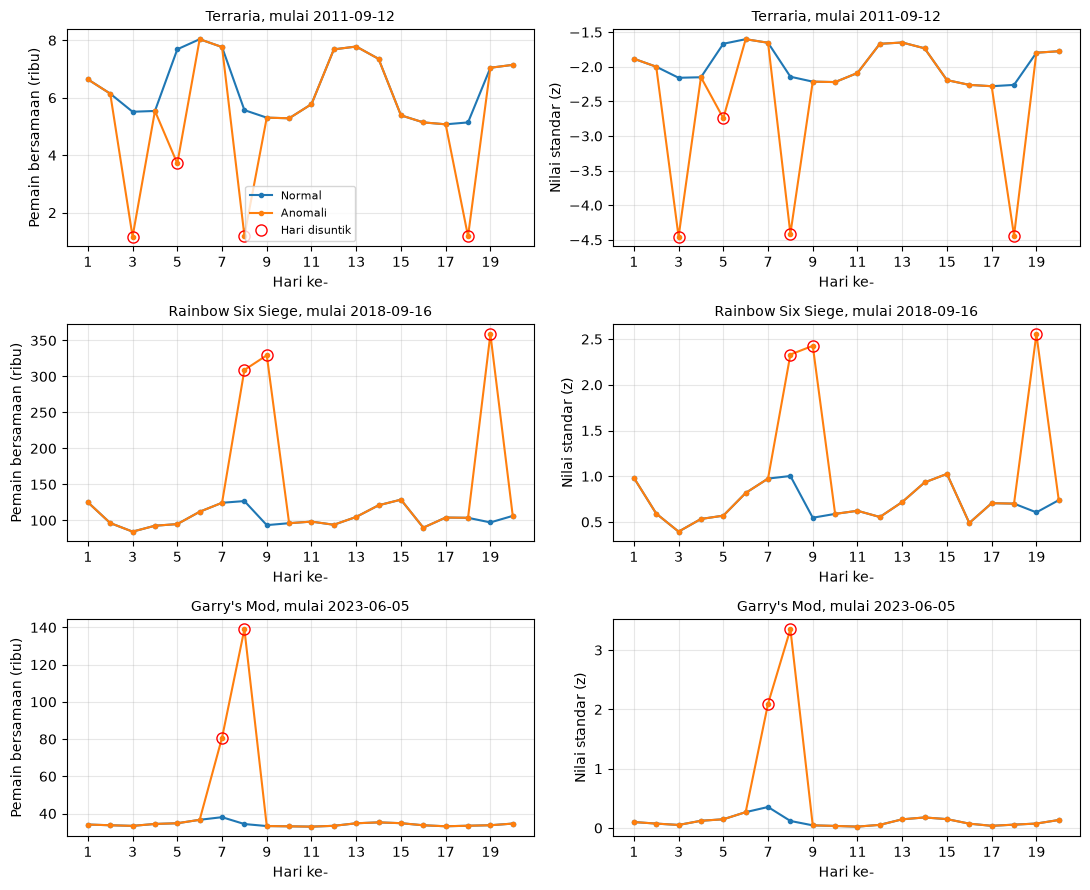

In [10]:
rng2 = np.random.default_rng(SEED + 1)
chosen = []
for gi in rng2.choice(len(GAMES), size=3, replace=False):
    cand = np.where((game_id == gi) & (~bump))[0]
    chosen.append(rng2.choice(cand))

fig, axes = plt.subplots(3, 2, figsize=(11, 9))
x = np.arange(1, SEG_LEN + 1)
for r, i in enumerate(chosen):
    for c, (a, b, unit) in enumerate([(seg_raw[i] / 1000, anom_raw[i] / 1000, 'Pemain bersamaan (ribu)'),
                                       (z_norm[i], z_anom[i], 'Nilai standar (z)')]):
        ax = axes[r, c]
        ax.plot(x, a, 'o-', ms=3, label='Normal'); ax.plot(x, b, 'o-', ms=3, label='Anomali')
        ax.plot(x[mask[i]], b[mask[i]], 'o', color='red', ms=8, mfc='none', label='Hari disuntik')
        ax.set_xticks(range(1, SEG_LEN + 1, 2)); ax.set_xlabel('Hari ke-'); ax.set_ylabel(unit); ax.grid(alpha=0.3)
        ax.set_title(f'{NAMES[GAMES[game_id[i]]]}, mulai {start_date[i]}', fontsize=10)
        if r == 0 and c == 0: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/'04_contoh_pasangan_segmen.png', dpi=150); plt.show()

## 10. Pemeriksaan sebelum lanjut

Beberapa pengecekan cepat: tidak ada nilai kosong, jumlah kelas seimbang, dan seberapa besar anomali yang disuntik terlihat di data terstandar.

In [11]:
assert not np.isnan(z_norm).any() and not np.isnan(z_anom).any()
assert (seg_raw > 0).all() and (anom_raw > 0).all()
assert k_anom.min() >= 1 and k_anom.max() <= 5
assert len(tr) + len(va) + len(te) == N and not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te))

sd_n, sd_a = z_norm.std(axis=1), z_anom.std(axis=1)
shift = np.abs(z_anom - z_norm)[mask]
print(f'Kelas: {N} normal dan {N} anomali (seimbang)')
print(f'SD per segmen (satuan z): normal {sd_n.mean():.2f} | anomali {sd_a.mean():.2f}')
print(f'Pergeseran titik yang disuntik (satuan z): rata-rata {shift.mean():.2f}, min {shift.min():.2f}, maks {shift.max():.2f}')
print(f'Segmen anomali dengan SD lebih kecil dari segmen normalnya: {(sd_a < sd_n).mean()*100:.1f}%')

Kelas: 1229 normal dan 1229 anomali (seimbang)
SD per segmen (satuan z): normal 0.23 | anomali 0.78
Pergeseran titik yang disuntik (satuan z): rata-rata 2.00, min 0.74, maks 3.72
Segmen anomali dengan SD lebih kecil dari segmen normalnya: 0.2%


## 11. Ringkasan dan menyimpan hasil

Lonjakan asli di segmen normal (persentasenya dicatat untuk bagian Insight) dan jumlah segmen per game dirangkum di tabel berikut.

In [12]:
summ = info.copy()
summ['jumlah_segmen'] = [int((game_id == gi).sum()) for gi in range(len(GAMES))]
summ['segmen_ada_lonjakan_asli'] = [int(bump[game_id == gi].sum()) for gi in range(len(GAMES))]
summ['persen_lonjakan_asli'] = (100 * summ['segmen_ada_lonjakan_asli'] / summ['jumlah_segmen']).round(1)
total = {'game': 'Total', 'jumlah_hari': summ.jumlah_hari.sum(), 'hari_hilang': summ.hari_hilang.sum(),
         'diisi_interpolasi': summ.diisi_interpolasi.sum(), 'tetap_kosong': summ.tetap_kosong.sum(),
         'jumlah_segmen': N, 'segmen_ada_lonjakan_asli': int(bump.sum()), 'persen_lonjakan_asli': round(100 * bump.mean(), 1)}
summ = pd.concat([summ, pd.DataFrame([total])], ignore_index=True)
summ.to_csv(RES/'ringkasan_data.csv', index=False)

pd.crosstab(pd.Series([NAMES[GAMES[i]] for i in game_id], name='game'), pd.Series(split, name='split'))[['train', 'val', 'test']].to_csv(RES/'ringkasan_split.csv')

np.savez_compressed(PROC/'segmen.npz', normal_raw=seg_raw, anomali_raw=anom_raw, normal_z=z_norm, anomali_z=z_anom,
                    mask_anomali=mask, faktor=factor, game_id=game_id, split=split, games=np.array(GAMES))
pd.DataFrame({'id': np.arange(N), 'game': [GAMES[i] for i in game_id], 'tanggal_mulai': start_date, 'split': split,
              'hari_diisi_interpolasi': n_filled, 'ada_lonjakan_asli': bump, 'jumlah_titik_anomali': k_anom}
             ).to_csv(PROC/'segmen_meta.csv', index=False)
summ

,game,mulai,akhir,jumlah_hari,hari_hilang,diisi_interpolasi,tetap_kosong,median_pemain,jumlah_segmen,segmen_ada_lonjakan_asli,persen_lonjakan_asli
0,Dark Souls 3,2016-04-12,2025-06-20,3357,0,0,0,9546.0,167,17,10.2
1,Euro Truck Simulator 2,2013-01-01,2025-06-20,4554,110,1,109,29242.0,220,18,8.2
2,Garry's Mod,2012-01-01,2025-06-20,4920,25,4,21,35501.0,244,17,7.0
3,Rainbow Six Siege,2015-12-01,2025-06-20,3490,0,0,0,71573.0,174,9,5.2
4,Stardew Valley,2016-02-26,2025-06-20,3403,0,0,0,27131.0,170,13,7.6
5,Terraria,2011-05-15,2025-06-20,5151,52,1,51,26767.0,254,51,20.1
6,Total,NaN,NaN,24875,187,6,181,NaN,1229,125,10.2
